In [1]:
# Load single-qubit data saved by the two-qubit calculation and print qubit-frequency detuning
import sys
from pathlib import Path
import numpy as np


In [2]:

# ../ham_data.py contains load_1q_data_for_2q
sys.path.insert(0, str(Path('..').resolve()))
import ham_data as hd

# Folder containing two_qubit_data.npz; change this path if you want another dataset.
folder_load = Path('../data/Two_qubit_data_Sorted_Untruc')

# load_1q_data_for_2q returns eigenvalues scaled by 2π, i.e. angular frequencies
# relative transition frequencies in GHz are therefore omega / (2π).
eval0, eval1, n_theta0, n_theta1 = hd.load_1q_data_for_2q(folder_load)

# Zero-pi logical qubit transition is |0> -> |2> in this project.
logical_ground = 0
logical_excited = 2

omega_q0 = eval0[logical_excited] - eval0[logical_ground]
omega_q1 = eval1[logical_excited] - eval1[logical_ground]
delta_omega = omega_q0 - omega_q1

freq_q0_ghz = omega_q0 / (2 * np.pi)
freq_q1_ghz = omega_q1 / (2 * np.pi)
detuning_ghz = delta_omega / (2 * np.pi)

print(f"Loaded 1Q data from: {folder_load}")
print(f"Zero-pi qubit 0 frequency |{logical_ground}>→|{logical_excited}>: {freq_q0_ghz:.9f} GHz")
print(f"Zero-pi qubit 1 frequency |{logical_ground}>→|{logical_excited}>: {freq_q1_ghz:.9f} GHz")
print(f"Detuning q0 - q1: {detuning_ghz:.9f} GHz ({detuning_ghz * 1e3:.6f} MHz)")
print(f"Angular detuning q0 - q1: {delta_omega:.9f} rad/ns")


Loaded 1Q data from: ../data/Two_qubit_data_Sorted_Untruc
Zero-pi qubit 0 frequency |0>→|2>: 3.443399830 GHz
Zero-pi qubit 1 frequency |0>→|2>: 3.409953268 GHz
Detuning q0 - q1: 0.033446562 GHz (33.446562 MHz)
Angular detuning q0 - q1: 0.210150945 rad/ns


99.9% coherent fidelity check
threshold log10(1-F) = -3.0
optimal detune = 0.013127000 GHz
frequency window = 0.012627000 to 0.013627000 GHz
frequency-window sampled points = 15
minimum F in frequency window = 0.99904341
maximum log10(1-F) in frequency window = -3.01927379
frequency window passes F >= 99.9%: True

optimal amp = 0.007880000
2% amp window = 0.007722400 to 0.008037600
amp-window sampled points = 5
minimum F in amp window = 0.99909232
maximum log10(1-F) in amp window = -3.04206945
drive-amplitude window passes F >= 99.9%: True


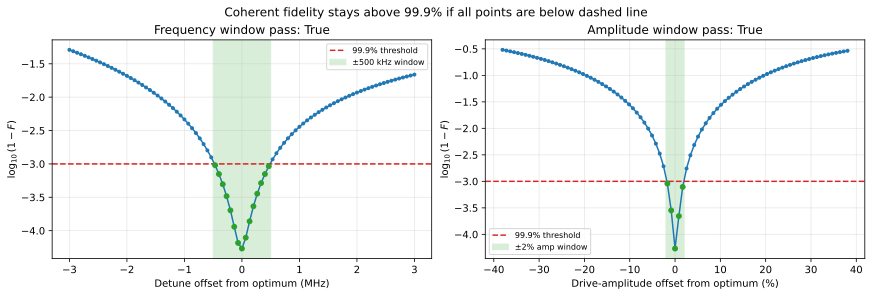

In [ ]:
# Check whether coherent fidelity stays above 99.9% in target windows
# Criterion: F >= 0.999  <=>  1-F <= 1e-3  <=>  log10(1-F) <= -3
import re
from pathlib import Path


import numpy as np
import matplotlib.pyplot as plt

log_path = Path("data/sensitivity/sensitivity_truc30tg182_dim91.txt")
text = log_path.read_text()


def read_np_array(name, text=text):
    pattern = rf"{re.escape(name)}\s*=\s*np\.array\(\s*(\[.*?\])\s*\)"
    match = re.search(pattern, text, flags=re.S)
    if match is None:
        raise KeyError(f"Could not find {name} in {log_path}")
    return np.array(eval(match.group(1).replace(",\n", ",")), dtype=float)

amp = read_np_array("amp_sweep_col1")
detune_ghz = read_np_array("detune_sweep_col2_GHz")
amp_log_errors = read_np_array("amp_log_errors")
detune_log_errors = read_np_array("detune_log_errors")

threshold_log_error = np.log10(1 - 0.999)  # -3

# Use the best sampled point as the optimum for each 1D scan.
opt_amp_idx = int(np.argmin(amp_log_errors))
opt_detune_idx = int(np.argmin(detune_log_errors))
opt_amp = amp[opt_amp_idx]
opt_detune_ghz = detune_ghz[opt_detune_idx]

# Requested windows.
# Interpretation used here: "frequency window of about 500 kHz" = ±500 kHz around optimum.
# If you mean total width 500 kHz instead, change freq_half_width_mhz to 0.25.
freq_half_width_mhz = 0.5
freq_half_width_ghz = freq_half_width_mhz * 1e-3
amp_half_width = 0.02 * opt_amp

freq_mask = np.abs(detune_ghz - opt_detune_ghz) <= freq_half_width_ghz + 1e-15
amp_mask = np.abs(amp - opt_amp) <= amp_half_width + 1e-15

freq_pass = bool(np.all(detune_log_errors[freq_mask] <= threshold_log_error))
amp_pass = bool(np.all(amp_log_errors[amp_mask] <= threshold_log_error))

# Convert to fidelity for easier reporting.
detune_fidelity = 1 - 10**detune_log_errors
amp_fidelity = 1 - 10**amp_log_errors

print("99.9% coherent fidelity check")
print("=" * 60)
print(f"threshold log10(1-F) = {threshold_log_error:.1f}")
print(f"optimal detune = {opt_detune_ghz:.9f} GHz")
print(f"frequency window = {opt_detune_ghz - freq_half_width_ghz:.9f} to {opt_detune_ghz + freq_half_width_ghz:.9f} GHz")
print(f"frequency-window sampled points = {freq_mask.sum()}")
print(f"minimum F in frequency window = {detune_fidelity[freq_mask].min():.8f}")
print(f"maximum log10(1-F) in frequency window = {detune_log_errors[freq_mask].max():.8f}")
print(f"frequency window passes F >= 99.9%: {freq_pass}")
print()
print(f"optimal amp = {opt_amp:.9f}")
print(f"2% amp window = {opt_amp - amp_half_width:.9f} to {opt_amp + amp_half_width:.9f}")
print(f"amp-window sampled points = {amp_mask.sum()}")
print(f"minimum F in amp window = {amp_fidelity[amp_mask].min():.8f}")
print(f"maximum log10(1-F) in amp window = {amp_log_errors[amp_mask].max():.8f}")
print(f"drive-amplitude window passes F >= 99.9%: {amp_pass}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# Frequency/detune plot: x-axis shown as offset from optimum in MHz.
detune_offset_mhz = (detune_ghz - opt_detune_ghz) * 1e3
ax[0].plot(detune_offset_mhz, detune_log_errors, marker="o", ms=3)
ax[0].axhline(threshold_log_error, color="C3", ls="--", label="99.9% threshold")
ax[0].axvspan(-freq_half_width_mhz, freq_half_width_mhz, color="C2", alpha=0.18, label="±500 kHz window")
ax[0].scatter(detune_offset_mhz[freq_mask], detune_log_errors[freq_mask], color="C2", zorder=3, s=24)
ax[0].set_xlabel("Detune offset from optimum (MHz)")
ax[0].set_ylabel(r"$\log_{10}(1-F)$")
ax[0].set_title(f"Frequency window pass: {freq_pass}")
ax[0].grid(True, alpha=0.3)
ax[0].legend(fontsize=8)

# Drive-amplitude plot: x-axis shown as percent offset from optimum.
amp_offset_percent = (amp / opt_amp - 1) * 100
ax[1].plot(amp_offset_percent, amp_log_errors, marker="o", ms=3)
ax[1].axhline(threshold_log_error, color="C3", ls="--", label="99.9% threshold")
ax[1].axvspan(-2, 2, color="C2", alpha=0.18, label="±2% amp window")
ax[1].scatter(amp_offset_percent[amp_mask], amp_log_errors[amp_mask], color="C2", zorder=3, s=24)
ax[1].set_xlabel("Drive-amplitude offset from optimum (%)")
ax[1].set_ylabel(r"$\log_{10}(1-F)$")
ax[1].set_title(f"Amplitude window pass: {amp_pass}")
ax[1].grid(True, alpha=0.3)
ax[1].legend(fontsize=8)

fig.suptitle("Coherent fidelity stays above 99.9% if all points are below dashed line")
plt.show()


In [14]:
27.04/33.45

0.808370702541106

# Fig

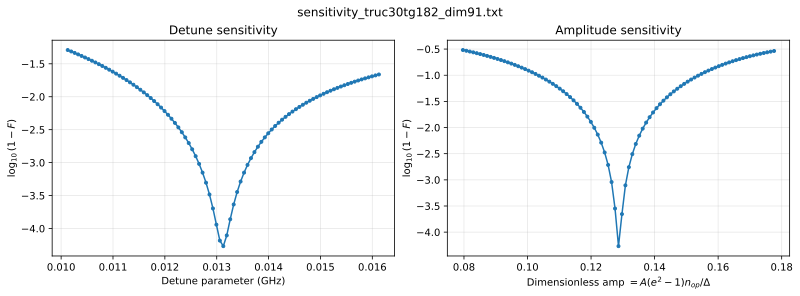

Loaded 91 amplitude points and 91 detune points
detune/(2π) = 33.45 MHz, nop = 0.537
dimensionless amp range: 0.0796627 to 0.177609


In [4]:
# Plot sensitivity data from text log
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

log_path = Path("data/sensitivity/sensitivity_truc30tg182_dim91.txt")
text = log_path.read_text()


def read_np_array(name, text=text):
    """Read arrays printed as: name = np.array([...]) from the log file."""
    pattern = rf"{re.escape(name)}\s*=\s*np\.array\(\s*(\[.*?\])\s*\)"
    match = re.search(pattern, text, flags=re.S)
    if match is None:
        raise KeyError(f"Could not find {name} in {log_path}")
    array_text = match.group(1).replace(",\n", ",")
    return np.array(eval(array_text), dtype=float)

amp = read_np_array("amp_sweep_col1")
detune_ghz = read_np_array("detune_sweep_col2_GHz")
amp_log_errors = read_np_array("amp_log_errors")
detune_log_errors = read_np_array("detune_log_errors")

# User-specified conversion:
# dimensionless_amp = amp * (e**2 - 1) * nop / detune,
# with nop=0.537 and detune/(2*pi)=33.45 MHz.
nop = 0.537
detune_over_2pi_mhz = 33.45
detune_ang_ghz = 2 * np.pi * detune_over_2pi_mhz * 1e-3  # angular detune in GHz
amp_dimensionless = amp * (np.e**2 - 1) * nop / detune_ang_ghz

fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

ax[0].plot(detune_ghz, detune_log_errors, marker="o", ms=3)
ax[0].set_xlabel("Detune parameter (GHz)")
ax[0].set_ylabel(r"$\log_{10}(1-F)$")
ax[0].set_title("Detune sensitivity")
ax[0].grid(True, alpha=0.3)

ax[1].plot(amp_dimensionless, amp_log_errors, marker="o", ms=3)
ax[1].set_xlabel(r"Dimensionless amp $= A(e^2-1)n_{op}/\Delta$")
ax[1].set_ylabel(r"$\log_{10}(1-F)$")
ax[1].set_title("Amplitude sensitivity")
ax[1].grid(True, alpha=0.3)

fig.suptitle(log_path.name)
plt.show()

print(f"Loaded {len(amp)} amplitude points and {len(detune_ghz)} detune points")
print(f"detune/(2π) = {detune_over_2pi_mhz} MHz, nop = {nop}")
print(f"dimensionless amp range: {amp_dimensionless.min():.6g} to {amp_dimensionless.max():.6g}")


In [13]:
0.13*6.28

0.8164

In [7]:
amp[45]

0.00788

In [8]:
len(amp)

91

In [9]:
detune_ang_ghz

0.21017254852515718

 /tmp/ipykernel_1279077/2844615196.py: 33UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
 /tmp/ipykernel_1279077/2844615196.py: 41

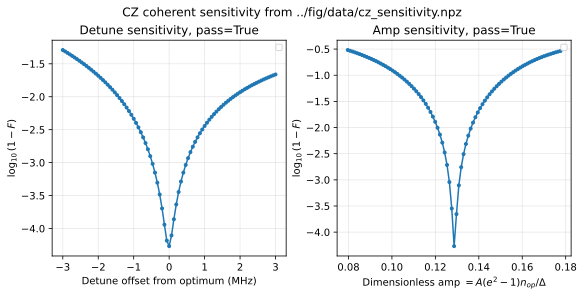

In [10]:
# Import CZ sensitivity data from NPZ and plot
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

npz_path = Path("../figure/data/cz_sensitivity.npz")
data = np.load(npz_path)

amp = data["amp"]
amp_dimensionless = data["amp_dimensionless"]
amp_log_errors = data["amp_log_errors"]
detune_ghz = data["detune_ghz"]
detune_mhz = data["detune_mhz"]
detune_log_errors = data["detune_log_errors"]

threshold_log_error = float(data["threshold_log_error"])
opt_amp = float(data["opt_amp"])
opt_detune_ghz = float(data["opt_detune_ghz"])
freq_half_width_mhz = float(data["freq_half_width_mhz"])
amp_percent_half_width = float(data["amp_percent_half_width"])
freq_mask = data["freq_mask"].astype(bool)
amp_mask = data["amp_mask"].astype(bool)

fig, ax = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

# Detune plot: log error vs detune offset in MHz.
detune_offset_mhz = (detune_ghz - opt_detune_ghz) * 1e3
ax[0].plot(detune_offset_mhz, detune_log_errors, marker="o", ms=3)
ax[0].set_xlabel("Detune offset from optimum (MHz)")
ax[0].set_ylabel(r"$\log_{10}(1-F)$")
ax[0].set_title(f"Detune sensitivity, pass={freq_pass}")
ax[0].grid(True, alpha=0.3)
ax[0].legend(fontsize=8)

# Amplitude plot: log error vs dimensionless amplitude.
ax[1].plot(amp_dimensionless, amp_log_errors, marker="o", ms=3)
ax[1].set_xlabel(r"Dimensionless amp $= A(e^2-1)n_{op}/\Delta$")
ax[1].set_ylabel(r"$\log_{10}(1-F)$")
ax[1].set_title(f"Amp sensitivity, pass={amp_pass}")
ax[1].grid(True, alpha=0.3)
ax[1].legend(fontsize=8)

fig.suptitle("CZ coherent sensitivity from ../fig/data/cz_sensitivity.npz")
plt.show()

# ZZ Rate

In [11]:
# Load the truncated two-qubit spectrum and calculate the static ZZ rate
import sys
from pathlib import Path

import numpy as np

# ham_data.py is in the parent directory of this notebook.
sys.path.insert(0, str(Path('..').resolve()))
import ham_data as hd

# load_two_qubit_data returns eval_tot in angular-frequency units (2π GHz).
folder_load = Path('../data/Two_qubit_data_Sorted_Truc')
(
    hspace_full,
    eket_tot,
    eval_tot,
    n_theta0,
    n_theta1,
    n_theta0_dress,
    n_theta1_dress,
    hspace_0,
    hspace_1,
    hspace_n_theta1,
    hspace_n_theta2,
    logi_state,
) = hd.load_two_qubit_data(folder_load, return_full=False)

# The logical states are |00>, |01>, |10>, and |11>, represented here by
# the zero-pi levels 0 and 2.  Static ZZ: zeta = E11 - E10 - E01 + E00.
logical_indices = {state: hspace_full.index(state) for state in logi_state}
E00, E01, E10, E11 = (eval_tot[logical_indices[state]] for state in logi_state)
zz_angular = E11 - E10 - E01 + E00
zz_ghz = zz_angular / (2 * np.pi)

print(f"Loaded two-qubit data from: {folder_load / 'two_qubit_data.npz'}")
for state in logi_state:
    idx = logical_indices[state]
    print(f"E[{state}] / (2π) = {eval_tot[idx] / (2 * np.pi):.12f} GHz (index {idx})")
print(f"ZZ / (2π) = {zz_ghz:.12e} GHz")
print(f"ZZ / (2π) = {zz_ghz * 1e6:.6f} kHz")
print(f"|ZZ| / (2π) = {abs(zz_ghz) * 1e6:.6f} kHz")


Loaded two-qubit data from: ../data/Two_qubit_data_Sorted_Truc/two_qubit_data.npz
E[0-0] / (2π) = 0.000000000000 GHz (index 0)
E[0-2] / (2π) = 3.409961712114 GHz (index 3)
E[2-0] / (2π) = 3.443405880112 GHz (index 4)
E[2-2] / (2π) = 6.853367421447 GHz (index 13)
ZZ / (2π) = -1.707788929844e-07 GHz
ZZ / (2π) = -0.170779 kHz
|ZZ| / (2π) = 0.170779 kHz


# Relative fidelity difference from truncation


$n_\theta$ driving (f_157_charge vs f_1000)
  average absolute difference = 2.125086e-05
  maximum absolute difference = 2.927802e-04
  average relative gate-error difference = 1.156942e-02
  maximum relative gate-error difference = 5.562035e-02
  maximum relative gate-error difference at tg = 119.917464 ns

$n_\phi$ driving (f_charge_160_npz vs f_1000)
  average absolute difference = 8.185830e-04
  maximum absolute difference = 5.094540e-03
  average relative gate-error difference = 4.594309e-02
  maximum relative gate-error difference = 1.469465e-01
  maximum relative gate-error difference at tg = 90.009744 ns



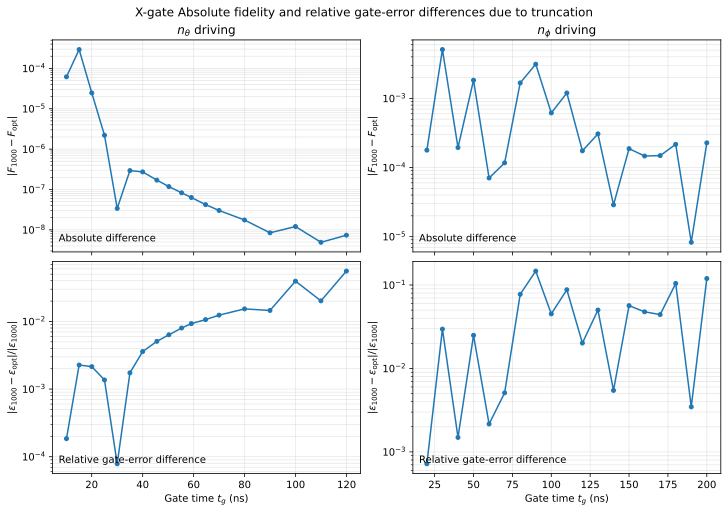

In [12]:
# Compare optimized-truncation fidelity with the 1000-state reference
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Entries named f_* in these files are log10(1 - F), not F itself.
data_dir = Path('../figure/data')
datasets = {
    r'$n_\theta$ driving': {
        'path': data_dir / 'data_xgate_theta_mstep_3e4_npz.txt',
        'optimized_column': 'f_157_charge',
    },
    r'$n_\phi$ driving': {
        'path': data_dir / 'data_xgate_phi_mstep_1e3_npz.txt',
        'optimized_column': 'f_charge_160_npz',
    },
}

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex='col', constrained_layout=True)
difference_results = {}

for column, (label, config) in enumerate(datasets.items()):
    data = np.genfromtxt(config['path'], delimiter=',', names=True)

    # Convert log10 gate errors to fidelities before taking their difference.
    error_1000 = 10.0**data['f_1000']
    error_optimized = 10.0**data[config['optimized_column']]
    fidelity_1000 = 1.0 - error_1000
    fidelity_optimized = 1.0 - error_optimized

    # Absolute fidelity difference equals the absolute gate-error difference.
    absolute_difference = np.abs(fidelity_1000 - fidelity_optimized)
    # Normalize by the reference gate error, which spans multiple orders of magnitude.
    relative_difference = np.abs(error_1000 - error_optimized) / np.abs(error_1000)

    difference_results[label] = {
        'absolute': absolute_difference,
        'relative': relative_difference,
    }

    print(f"{label} ({config['optimized_column']} vs f_1000)")
    print(f"  average absolute difference = {absolute_difference.mean():.6e}")
    print(f"  maximum absolute difference = {absolute_difference.max():.6e}")
    print(f"  average relative gate-error difference = {relative_difference.mean():.6e}")
    print(f"  maximum relative gate-error difference = {relative_difference.max():.6e}")
    print(f"  maximum relative gate-error difference at tg = "
          f"{data['tg'][relative_difference.argmax()]:.6f} ns")
    print()

    axes[0, column].semilogy(data['tg'], absolute_difference, 'o-', ms=4)
    axes[0, column].set_title(label)
    axes[0, column].set_ylabel(r'$|F_{1000}-F_{\mathrm{opt}}|$')

    axes[1, column].semilogy(data['tg'], relative_difference, 'o-', ms=4)
    axes[1, column].set_xlabel(r'Gate time $t_g$ (ns)')
    axes[1, column].set_ylabel(
        r'$|\epsilon_{1000}-\epsilon_{\mathrm{opt}}|/|\epsilon_{1000}|$'
    )

    for ax in axes[:, column]:
        ax.grid(True, which='both', alpha=0.3)

axes[0, 0].text(0.02, 0.05, 'Absolute difference', transform=axes[0, 0].transAxes)
axes[0, 1].text(0.02, 0.05, 'Absolute difference', transform=axes[0, 1].transAxes)
axes[1, 0].text(0.02, 0.05, 'Relative gate-error difference', transform=axes[1, 0].transAxes)
axes[1, 1].text(0.02, 0.05, 'Relative gate-error difference', transform=axes[1, 1].transAxes)
fig.suptitle('X-gate Absolute fidelity and relative gate-error differences due to truncation')
plt.show()


## CZ coherent pulse sensitivity — current phase correction (182 ns)
Standalone section: run the following cells in order. No pulse re-optimization is
performed. The reference pulse is selected from the supplied optimization table.
Solid curves optimize local Z at each point; dashed curves keep the nominal local-Z
calibration fixed. Both include leakage. The 99.9% criterion is tested, not assumed.


In [18]:
# ================= CENTRAL CONFIGURATION =================
import os
for _key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[_key] = '1'
os.environ.setdefault('MPLCONFIGDIR', '/tmp/cz-sensitivity-mpl')
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'cz/scripts/run_2q_fidelity.py').exists())
sys.path.insert(0, str(ROOT / 'cz/scripts'))
import run_2q_fidelity as sim
import qutip as qt

N_TRUC = 200
WORKERS = 50
TARGET_TG_NS = 182.0
PULSE_FILE = ROOT / 'figure/data/pulse_params_noise_scaling.txt'
OUT = ROOT / 'cz/data/coherent_pulse_sensitivity_noise_pulses_n200_tg182'
DETUNE_DEVIATION_MHZ = np.round(np.linspace(-1., 1., 101), 12)
AMPLITUDE_RELATIVE_DEVIATION = np.round(np.linspace(-.05, .05, 101), 12)
MAX_STEP_NS = 1e-3
ATOL = RTOL = 1e-10
OUT.mkdir(parents=True, exist_ok=True)


In [19]:
# ================= MODEL / WAVEFORM EDIT AREA =================
# Same charge-picked Hamiltonian and Gaussian drive as run_2q_fidelity.py.
cfg = sim.get_config()
cfg.update(cz_run=True, calculate_ideal=True, calculate_noise=False,
           reduced_model='charge_pick', use_qt_fidelity=False,
           folder_load=str(ROOT / 'data/Two_qubit_data_Sorted_Truc'))
table = sim._load_cz_pulse_params(PULSE_FILE)
base = table[np.argmin(np.abs(table[:, 0] - TARGET_TG_NS))].copy()
assert abs(base[0] - TARGET_TG_NS) < 1
_data = sim.load_system_data(cfg)
_gate = sim.select_gate_quantities(cfg, _data)
_indices = _data['hspace_n_theta1'][:N_TRUC]
_states = [_data['hspace_full'][i] for i in _indices]
LOGICAL_IDX = [_states.index(s) for s in _data['logi_state']]
H, _eket = sim.ut.build_hamiltonian_2q(True, _indices, _data['eval_tot'],
                                       _data['eket_tot'], _gate['drive_term'])
W_TARGET = float(_gate['W_20_50'])
del _data, _gate, _eket
# MHz -> GHz is 1e-3. The Hamiltonian helper adds 2*pi exactly once.
records = []
for i, delta in enumerate(DETUNE_DEVIATION_MHZ):
    p = base.copy(); p[2] += delta * 1e-3
    records.append(dict(scan='detuning', index=i, deviation=float(delta), params=p.tolist()))
for i, rel in enumerate(AMPLITUDE_RELATIVE_DEVIATION):
    p = base.copy(); p[1] *= 1 + rel
    records.append(dict(scan='amplitude', index=i, deviation=float(rel), params=p.tolist()))
_metadata = dict(n_truc=N_TRUC, base_params=base.tolist(), max_step_ns=MAX_STEP_NS,
                 atol=ATOL, rtol=RTOL, states=_states,
                 source_hash=hashlib.sha256((ROOT/'utils_2Q_gate_zp.py').read_bytes()).hexdigest(),
                 data_stat=[(ROOT/'data/Two_qubit_data_Sorted_Truc/two_qubit_data.npz').stat().st_size,
                            (ROOT/'data/Two_qubit_data_Sorted_Truc/two_qubit_data.npz').stat().st_mtime_ns])
SIGNATURE = hashlib.sha256(json.dumps(_metadata,sort_keys=True).encode()).hexdigest()
(OUT / 'config.json').write_text(json.dumps(dict(_metadata, workers=WORKERS, signature=SIGNATURE),indent=2))
print('Nominal [tg ns, amplitude, detune GHz]:', base)
print('n_truc:', N_TRUC, '; workers:', WORKERS)


In [20]:
# ================= INDEPENDENT IDEAL SOLVES / CHECKPOINTS =================
def ideal_point(p, name, hamiltonian, w_target, logical_idx, out_dir, signature,
                max_step, atol, rtol):
    import qutip as qt
    import utils_2Q_gate_zp as ut
    path = Path(out_dir) / (name + '.npz')
    p = np.asarray(p, dtype=float)
    if path.exists():
        with np.load(path) as saved:
            if str(saved['signature'].item()) == signature and np.array_equal(saved['params'],p):
                return saved['U']
    args = dict(drive_amp_A=float(p[1]), drive_freq_A=float(w_target + 2*np.pi*p[2]),
                gate_time=float(p[0]))
    options = qt.Options(max_step=max_step, nsteps=1000000, atol=atol, rtol=rtol,
                         num_cpus=1, normalize_output=False)
    u = ut.get_propagator(hamiltonian, [0.,float(p[0])], 1, [], args,
                          logical_idx, options, options).full()
    temporary = path.with_suffix('.tmp.npz')
    np.savez(temporary, U=u, params=p, signature=signature)
    os.replace(temporary,path)
    return u

_nominal = ideal_point(base, 'nominal', H, W_TARGET, LOGICAL_IDX, str(OUT), SIGNATURE,
                       MAX_STEP_NS, ATOL, RTOL)
_, NOMINAL_Z_ANGLES, nominal_fidelity, _, _ = sim.ut.cz_phase_optimize_channel(
    [qt.Qobj(_nominal,dims=[[2,2],[2,2]])])
UZ_NOMINAL = qt.tensor(sim.ut.rz(float(NOMINAL_Z_ANGLES[0])),
                      sim.ut.rz(float(NOMINAL_Z_ANGLES[1])))
print('Nominal fidelity:', nominal_fidelity, '; fixed Z angles:', NOMINAL_Z_ANGLES)
# Compute 200 off-center points; the two scan centers share the nominal solve.
_jobs = [r for r in records if abs(r['deviation']) > 1e-14]
with parallel_config(backend='loky', inner_max_num_threads=1):
    _completed = Parallel(n_jobs=WORKERS, verbose=10)(
        delayed(ideal_point)(r['params'], f"{r['scan']}_{r['index']:03d}", H,
                            W_TARGET, LOGICAL_IDX, str(OUT), SIGNATURE,
                            MAX_STEP_NS, ATOL, RTOL) for r in _jobs)
_solutions = {(r['scan'],r['index']):u for r,u in zip(_jobs,_completed)}
_rows = []
for r in records:
    u = _nominal if abs(r['deviation']) < 1e-14 else _solutions[(r['scan'],r['index'])]
    k = qt.Qobj(u,dims=[[2,2],[2,2]])
    _, angles, f_opt, _, _ = sim.ut.cz_phase_optimize_channel([k])
    f_fixed = sim.ut.average_gate_fidelity_trace_decreasing([UZ_NOMINAL*k],sim.ut.cz_gate())
    _rows.append(dict(scan=r['scan'], deviation=r['deviation'], tg_ns=base[0],
                      amplitude=r['params'][1], detune_ghz=r['params'][2],
                      fidelity_optimized_z=f_opt, gate_error_optimized_z=1-f_opt,
                      fidelity_fixed_z=f_fixed, gate_error_fixed_z=1-f_fixed,
                      z_q0=angles[0], z_q1=angles[1]))
results = pd.DataFrame(_rows)
results.to_csv(OUT / 'all_results.csv',index=False)
print('Saved',len(results),'scan points to',OUT)


In [3]:
df = np.load(_npz_opt_path)
df.files

['source_log',
 'base_params',
 'tg_ns',
 'tg_log_errors',
 'amp',
 'amp_dimensionless',
 'amp_log_errors',
 'detune_ghz',
 'detune_mhz',
 'detune_log_errors',
 'nop',
 'detune_over_2pi_mhz',
 'detune_ang_ghz',
 'threshold_fidelity',
 'threshold_log_error',
 'opt_amp',
 'opt_detune_ghz',
 'freq_half_width_mhz',
 'freq_mask',
 'amp_percent_half_width',
 'amp_mask']

In [4]:

data = np.load("../figure/data/cz_new_phase_20261112/cz_sensitivity.npz")

for key in data.files:
    print(f"{key}: shape={data[key].shape}, dtype={data[key].dtype}")

source_log: shape=(), dtype=<U74
base_params: shape=(3,), dtype=float64
tg_ns: shape=(1,), dtype=float64
tg_log_errors: shape=(1,), dtype=float64
amp: shape=(101,), dtype=float64
amp_dimensionless: shape=(101,), dtype=float64
amp_log_errors: shape=(101,), dtype=float64
detune_ghz: shape=(101,), dtype=float64
detune_mhz: shape=(101,), dtype=float64
detune_log_errors: shape=(101,), dtype=float64
nop: shape=(), dtype=float64
detune_over_2pi_mhz: shape=(), dtype=float64
detune_ang_ghz: shape=(), dtype=float64
threshold_fidelity: shape=(), dtype=float64
threshold_log_error: shape=(), dtype=float64
opt_amp: shape=(), dtype=float64
opt_detune_ghz: shape=(), dtype=float64
freq_half_width_mhz: shape=(), dtype=float64
freq_mask: shape=(101,), dtype=bool
amp_percent_half_width: shape=(), dtype=float64
amp_mask: shape=(101,), dtype=bool


Plot data: /home/zlqed/two_qubit_gate/zeropi/two_qubit_gate_clean/figure/data/cz_new_phase_20261112/cz_sensitivity.npz and /home/zlqed/two_qubit_gate/zeropi/two_qubit_gate_clean/figure/data/cz_new_phase_20261112/cz_sensitivity_fixed_z.npz


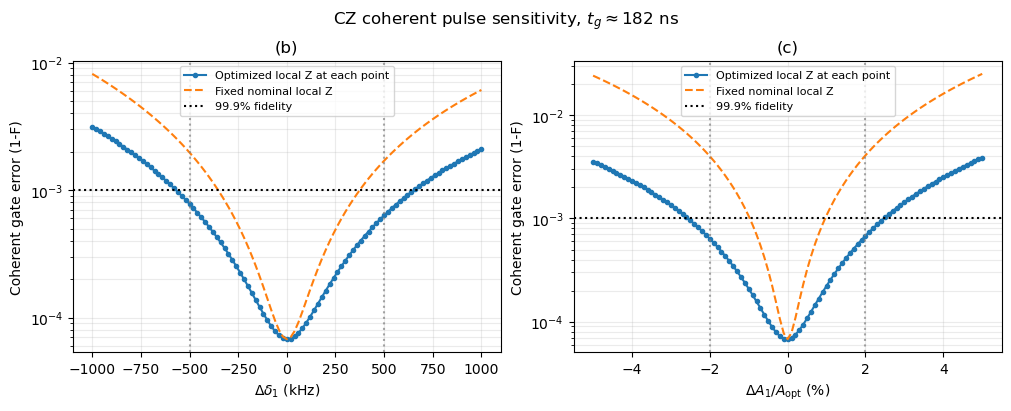

     scan phase_correction  min_sampled_fidelity  worst_deviation  passes_99p9_percent
 detuning      optimized_z              0.999221            -0.50                 True
 detuning          fixed_z              0.998029            -0.50                False
amplitude      optimized_z              0.999321             0.02                 True
amplitude          fixed_z              0.995919             0.02                False
Tests refer to sampled points in ±500 kHz and ±2% windows; not a continuous-domain proof.


In [1]:
# ================= PANELS (b), (c): EXPORTED NEW-PHASE DATA =================
# Standalone plotting cell; does not depend on a previous OUT variable.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'cz/scripts/run_2q_fidelity.py').exists())
FIGURE_DATA = ROOT/'figure/data/cz_new_phase_20261112'
_npz_opt_path = FIGURE_DATA/'cz_sensitivity.npz'
_npz_fixed_path = FIGURE_DATA/'cz_sensitivity_fixed_z.npz'
with np.load(_npz_opt_path) as _saved:
    _opt = {k: _saved[k].copy() for k in _saved.files}
with np.load(_npz_fixed_path) as _saved:
    _fixed = {k: _saved[k].copy() for k in _saved.files}
for _key in ('base_params', 'amp', 'detune_ghz'):
    np.testing.assert_allclose(_opt[_key], _fixed[_key], rtol=0, atol=1e-14)
_base = _opt['base_params']
_rows = []
for _scan, _deviation, _key in (
    ('detuning', (_opt['detune_ghz']-_base[2])*1000., 'detune_log_errors'),
    ('amplitude', (_opt['amp']-_base[1])/_base[1], 'amp_log_errors')):
    _eo = np.power(10.0, _opt[_key])
    _ef = np.power(10.0, _fixed[_key])
    _rows.extend(dict(scan=_scan, deviation=x,
                      fidelity_optimized_z=1-eo, gate_error_optimized_z=eo,
                      fidelity_fixed_z=1-ef, gate_error_fixed_z=ef)
                 for x, eo, ef in zip(_deviation, _eo, _ef))
results = pd.DataFrame(_rows)
print('Plot data:', _npz_opt_path, 'and', _npz_fixed_path)
fig, axes = plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
_summary = []
for ax,scan,scale,limit,label,panel in [
    (axes[0],'detuning',1000.,.5,r'$\Delta\delta_1$ (kHz)','(b)'),
    (axes[1],'amplitude',100.,.02,r'$\Delta A_1/A_{\mathrm{opt}}$ (%)','(c)')]:
    d = results[results.scan==scan].sort_values('deviation')
    x = d.deviation.to_numpy()*scale
    ax.semilogy(x,d.gate_error_optimized_z,'o-',ms=3,label='Optimized local Z at each point')
    ax.semilogy(x,d.gate_error_fixed_z,'--',label='Fixed nominal local Z')
    ax.axhline(1e-3,color='k',ls=':',label='99.9% fidelity')
    for sign in (-1,1): ax.axvline(sign*limit*scale,color='gray',ls=':',alpha=.7)
    ax.set(xlabel=label,ylabel='Coherent gate error (1-F)',title=panel)
    ax.grid(True,which='both',alpha=.25)
    ax.legend(fontsize=8)
    window = d[d.deviation.abs() <= limit+1e-12]
    assert len(window) and abs(window.deviation.min()+limit)<1e-10 and abs(window.deviation.max()-limit)<1e-10
    for mode in ('optimized_z','fixed_z'):
        fmin=float(window['fidelity_'+mode].min())
        worst=window.loc[window['fidelity_'+mode].idxmin(),'deviation']
        _summary.append(dict(scan=scan,phase_correction=mode,min_sampled_fidelity=fmin,
                             worst_deviation=worst,passes_99p9_percent=fmin>=.999))
fig.suptitle(r'CZ coherent pulse sensitivity, $t_g\approx182$ ns')
for ext in ('png','pdf'): fig.savefig(FIGURE_DATA/f'coherent_sensitivity_bc.{ext}',dpi=180)
plt.show()
summary = pd.DataFrame(_summary)
summary.to_csv(FIGURE_DATA/'robustness_summary.csv',index=False)
print(summary.to_string(index=False))
print('Tests refer to sampled points in ±500 kHz and ±2% windows; not a continuous-domain proof.')
